In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pingouin as pg

men_df = pd.read_csv('csv_files/men_results.csv')
women_df = pd.read_csv('csv_files/women_results.csv')

In [2]:
print(men_df.info())
print('-' * 20)
print(women_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 44353 entries, 0 to 44352
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  44353 non-null  int64
 1   date        44353 non-null  str  
 2   home_team   44353 non-null  str  
 3   away_team   44353 non-null  str  
 4   home_score  44353 non-null  int64
 5   away_score  44353 non-null  int64
 6   tournament  44353 non-null  str  
dtypes: int64(3), str(4)
memory usage: 2.4 MB
None
--------------------
<class 'pandas.DataFrame'>
RangeIndex: 4884 entries, 0 to 4883
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  4884 non-null   int64
 1   date        4884 non-null   str  
 2   home_team   4884 non-null   str  
 3   away_team   4884 non-null   str  
 4   home_score  4884 non-null   int64
 5   away_score  4884 non-null   int64
 6   tournament  4884 non-null   str  
dtypes: int64(3), str(4)
memory us

##### From the details above, we can confirm that the dependent variables are `home_score` and `away_score` = `total_score`(what we measure). And the independent variables is tournament (FIFA World Cup)

### Converting the date column to datetime. (According to the instruction)

In [3]:
men_df['date'] = pd.to_datetime(men_df['date'])
men_df['date'].dtype

dtype('<M8[us]')

In [4]:
women_df['date'] = pd.to_datetime(women_df['date'])
women_df['date'].dtype

dtype('<M8[us]')

In [5]:
men_df['tournament'].value_counts()['FIFA World Cup']

np.int64(964)

In [6]:
women_df['tournament'].value_counts()['FIFA World Cup']

np.int64(284)

### Filtering data 

Filtering out the date for after the year 2002 and the tournament to FIFA world cup

In [7]:
men_subset = men_df[(men_df['date'] >= '2002-01-01') & (men_df['tournament'] == 'FIFA World Cup')] 

In [8]:
women_subset = women_df[(women_df['date'] >= '2002-01-01') & (women_df['tournament'] == 'FIFA World Cup')]

In [9]:
men_subset.shape

(384, 7)

In [10]:
women_subset.shape

(200, 7)

In [11]:
men_subset['total_goals'] = men_subset['home_score'] + men_subset['away_score']

In [12]:
women_subset['total_goals'] = women_subset['home_score'] + women_subset['away_score']

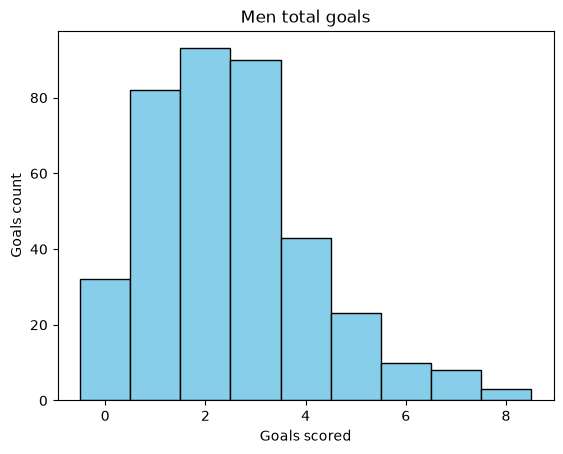

In [13]:
bins = np.arange(-0.5, men_subset['total_goals'].max() + 1.5, 1)

plt.hist(men_subset['total_goals'], color='skyblue', edgecolor='black', bins = bins)
plt.xlabel('Goals scored')
plt.ylabel('Goals count')
plt.title('Men total goals')
plt.show()

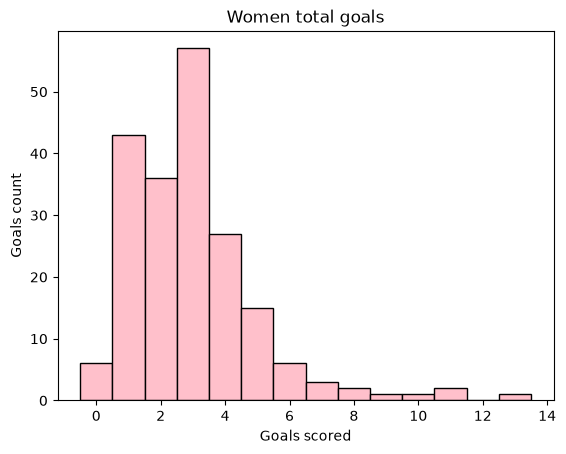

In [14]:
bins = np.arange(-0.5, women_subset['total_goals'].max()+ 1.5, 1)


plt.hist(women_subset['total_goals'], color='pink', edgecolor='black', bins=bins)
plt.xlabel('Goals scored')
plt.ylabel('Goals count')
plt.title('Women total goals')
plt.show()

In [15]:
print(men_subset['total_goals'].shape[0])
print(women_subset['total_goals'].shape[0])

384
200


In [16]:
print("Mean of men's total goal: ",men_subset['total_goals'].mean())
print("Mean of women's total goals: ", women_subset['total_goals'].mean())

Mean of men's total goal:  2.5130208333333335
Mean of women's total goals:  2.98


#### From the optput we can use either t-test or Mann-Whitney U tests for hypothesis testing.

### Using t-test

In [20]:
test_output = pg.ttest(
    x=women_subset['total_goals'],
    y= men_subset['total_goals'],
    paired = False,
    alternative = 'two-sided',
    correction = True
)
print(test_output)

               T         dof alternative     p_val          CI95   cohen_d  \
T_test  2.812823  340.102801   two-sided  0.005196  [0.14, 0.79]  0.261228   

           power   BF10  
T_test  0.848673  4.463  


In [27]:
alpha = 0.1 #significance level
p_value = test_output['p_val'].iloc[0]

if p_value < alpha:
    result = 'reject'
else:
    result = 'fail to reject'

result_dict = {"p_val": float(p_value), "result": result}
print(result_dict)

{'p_val': 0.005196144800974298, 'result': 'reject'}
